# Retail Sales: data audit and exploratory analysis

## Objectives

We investigate the structure and quality of the retail data before building
forecasting models. We examine temporal coverage, relationships between tables,
missing values, duplicate keys, returns, and unusual prices.

We then explore sales patterns across stores, categories, and products,
including trends, seasonality, promotions, and changes in assortment.

We use these findings to define a forecasting task and a chronological
evaluation strategy with time-series cross-validation. We reserve a final
holdout period before exploring sales patterns or selecting models.

In [1]:
from pathlib import Path
import gc
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": COLORS["dark"],
        "text.color": COLORS["dark"],
        "grid.alpha": 0.25,
    },
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Source files and table structure

We first locate the source files and inspect their schemas using small samples.
We avoid loading every table into memory at once.

At this stage, we check file availability and column types. We do not interpret
missing sales records as zero demand, remove negative values, or combine online
and other sales until we establish what these records represent.

In [2]:
working_dir = Path.cwd().resolve()
project_candidates = [working_dir, *working_dir.parents]

PROJECT_ROOT = next(
    (
        path
        for path in project_candidates
        if (path / "data" / "raw" / "retail").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/raw/retail/. "
        "Start Jupyter inside the project directory."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "retail"

EXPECTED_FILES = [
    "sales.csv",
    "online.csv",
    "catalog.csv",
    "stores.csv",
    "price_history.csv",
    "discounts_history.csv",
    "markdowns.csv",
    "actual_matrix.csv",
]

missing_files = [
    name for name in EXPECTED_FILES
    if not (DATA_DIR / name).is_file()
]

if missing_files:
    raise FileNotFoundError(f"Missing source files: {missing_files}")

file_inventory = pd.DataFrame(
    {
        "file": name,
        "size_mb": (DATA_DIR / name).stat().st_size / 1_000_000,
    }
    for name in EXPECTED_FILES
)

display(file_inventory)

samples = {}

for name in EXPECTED_FILES:
    sample = pd.read_csv(DATA_DIR / name, nrows=5_000)

    sample = sample.drop(columns=["Unnamed: 0"], errors="ignore")
    samples[Path(name).stem] = sample

    print(f"\n{'=' * 60}\n{name} — sample only")
    display(sample.head(3))
    display(
        sample.dtypes.astype(str)
        .rename("sample_dtype")
        .to_frame()
    )

,file,size_mb
0,sales.csv,379.235
1,online.csv,56.840
2,catalog.csv,25.253
3,stores.csv,0.000
4,price_history.csv,29.280
5,discounts_history.csv,341.483
6,markdowns.csv,0.426
7,actual_matrix.csv,1.115



sales.csv — sample only


,date,item_id,quantity,price_base,sum_total,store_id
0,2023-08-04,293375605257,1.000,47.860,47.860,1
1,2023-08-04,a66fdf2c0ae7,3.000,49.600,148.800,1
2,2023-08-04,daa46ef49b7a,0.822,379.000,311.540,1


,sample_dtype
date,str
item_id,str
quantity,float64
price_base,float64
sum_total,float64
store_id,int64



online.csv — sample only


,date,item_id,quantity,price_base,sum_total,store_id
0,2023-08-04,4aa8dbe05246,3.000,12.400,37.210,1
1,2023-08-04,4e0fbcf99cf9,2.000,56.270,112.540,1
2,2023-08-04,2e008b673129,2.000,56.270,112.540,1


... (15 outputs left out)

,sample_dtype
date,str
item_id,str
normal_price,float64
price,float64
quantity,float64
store_id,int64



actual_matrix.csv — sample only


,item_id,date,store_id
0,c578da8e8841,2019-10-17,1
1,4dd2b686802c,2019-10-17,1
2,16ade2e3fca9,2019-10-17,1


,sample_dtype
item_id,str
date,str
store_id,int64


## 2. Sales data quality and temporal coverage

We load the complete sales table and check missing values, invalid dates,
non-finite numeric values, and repeated records.

We test whether a date–store–item combination uniquely identifies a row.
Repeated combinations may represent multiple sales records, so we do not
remove them automatically.

We also inspect date coverage for each store. A day without records does not
necessarily mean zero sales: it may indicate closure or missing data.

In [3]:
SALES_COLUMNS = [
    "date", "item_id", "quantity",
    "price_base", "sum_total", "store_id",
]

sales = pd.read_csv(
    DATA_DIR / "sales.csv",
    usecols=SALES_COLUMNS,
    dtype={
        "date": "string",
        "item_id": "string",
        "store_id": "Int64",
        "quantity": "float64",
        "price_base": "float64",
        "sum_total": "float64",
    },
)

raw_dates = sales["date"]
parsed_dates = pd.to_datetime(
    raw_dates, format="%Y-%m-%d", errors="coerce"
)

invalid_date_count = int(
    (raw_dates.notna() & parsed_dates.isna()).sum()
)
sales["date"] = parsed_dates

print(f"Rows: {len(sales):,}")
print(
    "Memory usage: "
    f"{sales.memory_usage(deep=True).sum() / 1_000_000:,.1f} MB"
)

missing_summary = pd.DataFrame({
    "missing_count": sales.isna().sum(),
    "missing_pct": sales.isna().mean().mul(100),
})
display(missing_summary)

numeric_columns = ["quantity", "price_base", "sum_total"]
numeric_checks = []

for column in numeric_columns:
    values = sales[column]
    numeric_checks.append({
        "column": column,
        "infinite_count": int(np.isinf(values).sum()),
        "negative_count": int(values.lt(0).sum()),
        "zero_count": int(values.eq(0).sum()),
    })

display(pd.DataFrame(numeric_checks).set_index("column"))
print(f"Non-missing dates that failed parsing: {invalid_date_count:,}")

key = ["date", "store_id", "item_id"]

duplicate_summary = pd.Series({
    "exact_duplicate_rows_beyond_first":
        int(sales.duplicated().sum()),
    "repeated_key_rows_beyond_first":
        int(sales.duplicated(key).sum()),
    "all_rows_in_repeated_key_groups":
        int(sales.duplicated(key, keep=False).sum()),
}, name="count")

display(duplicate_summary.to_frame())

Rows: 7,432,685
Memory usage: 453.4 MB


,missing_count,missing_pct
date,0,0.000
item_id,0,0.000
quantity,0,0.000
price_base,0,0.000
sum_total,0,0.000
store_id,0,0.000


,infinite_count,negative_count,zero_count
column,,,
quantity,0,1160,2438
price_base,0,67,8026
sum_total,0,1610,6593


Non-missing dates that failed parsing: 0


,count
exact_duplicate_rows_beyond_first,0
repeated_key_rows_beyond_first,0
all_rows_in_repeated_key_groups,0


### Initial data quality findings

We found no missing values, invalid dates, or infinite numeric values in
7,432,685 sales records. Both full rows and date–store–item combinations
are unique, so no additional aggregation is required at this level.

However, the table contains negative and zero quantities, prices, and amounts.
Negative amounts occur more frequently than negative quantities, suggesting
that a single explanation may not cover all these records. We retain them
until we inspect their sign combinations and possible business meanings.

These checks confirm structural consistency, but they do not establish
whether the recorded values are correct or whether every expected observation
is present.

,first_date,last_date,observed_days,calendar_days_in_store_span,missing_days_in_store_span,coverage_pct
store_id,,,,,,
1,2022-08-28,2024-09-26,761,761,0,100.000
2,2022-08-28,2024-09-26,761,761,0,100.000
3,2022-08-28,2024-09-26,760,761,1,99.869
4,2023-12-13,2024-09-26,289,289,0,100.000


Store 1: 0 missing dates within its span. First examples: []
Store 2: 0 missing dates within its span. First examples: []
Store 3: 1 missing dates within its span. First examples: ['2022-10-16']
Store 4: 0 missing dates within its span. First examples: []


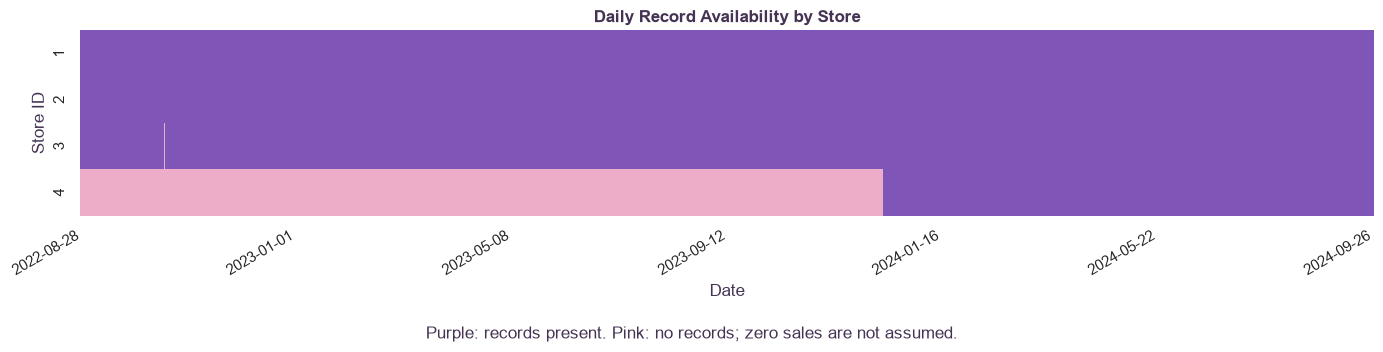

In [4]:
coverage_source = sales.dropna(subset=["date", "store_id"])

daily_record_counts = (
    coverage_source
    .groupby(["date", "store_id"], observed=True)
    .size()
    .rename("record_count")
    .unstack("store_id")
)

if daily_record_counts.empty:
    raise ValueError("No valid date–store records are available.")

full_calendar = pd.date_range(
    coverage_source["date"].min(),
    coverage_source["date"].max(),
    freq="D",
)

daily_record_counts = daily_record_counts.reindex(full_calendar)
daily_record_counts.index.name = "date"

coverage_rows = []
missing_dates_by_store = {}

for store_id in daily_record_counts.columns:
    observed_dates = daily_record_counts[store_id].dropna().index

    first_date = observed_dates.min()
    last_date = observed_dates.max()
    own_calendar = pd.date_range(first_date, last_date, freq="D")

    missing_dates = own_calendar.difference(observed_dates)
    missing_dates_by_store[store_id] = missing_dates

    coverage_rows.append({
        "store_id": store_id,
        "first_date": first_date,
        "last_date": last_date,
        "observed_days": len(observed_dates),
        "calendar_days_in_store_span": len(own_calendar),
        "missing_days_in_store_span": len(missing_dates),
        "coverage_pct": 100 * len(observed_dates) / len(own_calendar),
    })

store_coverage = (
    pd.DataFrame(coverage_rows)
    .set_index("store_id")
    .sort_index()
)

display(store_coverage)

for store_id, dates in missing_dates_by_store.items():
    examples = [date.strftime("%Y-%m-%d") for date in dates[:10]]
    print(
        f"Store {store_id}: {len(dates)} missing dates within its span. "
        f"First examples: {examples}"
    )

fig, ax = plt.subplots(figsize=(14, 3.5))

sns.heatmap(
    daily_record_counts.notna().T.astype(int),
    cmap=[COLORS["rose"], COLORS["purple"]],
    vmin=0,
    vmax=1,
    cbar=False,
    xticklabels=False,
    ax=ax,
)

tick_positions = np.unique(
    np.linspace(0, len(full_calendar) - 1, 7, dtype=int)
)

ax.set_xticks(tick_positions + 0.5)
ax.set_xticklabels(
    full_calendar[tick_positions].strftime("%Y-%m-%d"),
    rotation=30,
    ha="right",
)

ax.set_title("Daily Record Availability by Store")
ax.set_xlabel("Date")
ax.set_ylabel("Store ID")

fig.text(
    0.5, 0.01,
    "Purple: records present. Pink: no records; zero sales are not assumed.",
    ha="center",
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### Temporal coverage findings

Stores 1 and 2 have records on all 761 days between 2022-08-28 and
2024-09-26. Store 3 has one day without records: 2022-10-16.
We retain this date as missing rather than assuming zero sales.

Store 4 first appears on 2023-12-13 and has records on every subsequent
day. The data alone do not establish whether this is its opening date
or the beginning of data collection.

Combining all stores may introduce a change caused by store coverage.
We therefore examine stores 1–3 as a fixed group and analyse store 4
separately. Store-level daily coverage does not establish completeness
at the item level.

## 3. Final holdout reservation

We reserve the last 28 calendar days, from 2024-08-30 to 2024-09-26,
for final evaluation. This four-week horizon contains each weekday
exactly four times.

We use the preceding period for exploratory analysis and model development.
Model selection uses chronological cross-validation with 28-day validation
windows. We fit preprocessing steps separately within each training fold.

We do not use holdout sales values to select products, features,
transformations, or models. Final evaluation represents one four-week
period, so cross-validation is needed to assess performance at other origins.

In [5]:
FORECAST_HORIZON = 28
TEST_END = pd.Timestamp("2024-09-26")
TEST_START = TEST_END - pd.Timedelta(days=FORECAST_HORIZON - 1)

assert sales["date"].notna().all()
assert sales["date"].max() == TEST_END

sales_dev = sales.loc[sales["date"] < TEST_START].copy()

split_summary = pd.DataFrame([
    {
        "partition": "development",
        "start": sales_dev["date"].min(),
        "end": TEST_START - pd.Timedelta(days=1),
        "calendar_days": (
            TEST_START - sales_dev["date"].min()
        ).days,
    },
    {
        "partition": "final_test",
        "start": TEST_START,
        "end": TEST_END,
        "calendar_days": FORECAST_HORIZON,
    },
])

assert sales_dev["date"].max() < TEST_START
display(split_summary)

del sales, coverage_source
gc.collect()

,partition,start,end,calendar_days
0,development,2022-08-28,2024-08-29,733
1,final_test,2024-08-30,2024-09-26,28


20

## 4. Negative and zero values

We examine combinations of quantity, price, and amount signs to distinguish
different types of unusual records. These patterns may be consistent with
returns, adjustments, free items, or data issues, but they do not establish
the business meaning on their own.

We measure both the frequency and monetary magnitude of these records.
A small number of unusual rows may still have a substantial impact.

All checks in this section use the development period. We retain the
original values until we have enough evidence to define processing rules.

In [6]:
def value_sign(series):
    return np.select(
        [series.lt(0), series.eq(0), series.gt(0)],
        ["negative", "zero", "positive"],
        default="missing",
    )


sign_summary = (
    sales_dev
    .groupby(
        [
            value_sign(sales_dev["quantity"]),
            value_sign(sales_dev["price_base"]),
            value_sign(sales_dev["sum_total"]),
        ],
        sort=True,
    )
    .agg(
        rows=("item_id", "size"),
        net_amount=("sum_total", "sum"),
        absolute_amount=("sum_total", lambda s: s.abs().sum()),
    )
)

sign_summary.index.names = [
    "quantity_sign", "price_sign", "amount_sign"
]

sign_summary["rows_pct"] = (
    100 * sign_summary["rows"] / len(sales_dev)
)

total_absolute_amount = sales_dev["sum_total"].abs().sum()

sign_summary["absolute_amount_pct"] = (
    100 * sign_summary["absolute_amount"] / total_absolute_amount
    if total_absolute_amount > 0
    else np.nan
)

sign_summary = sign_summary.sort_values("rows", ascending=False)

display(sign_summary)

rows        net_amount  \
quantity_sign price_sign amount_sign                              
positive      positive   positive     7042182 5,351,867,776.150   
              zero       zero            5480             0.000   
negative      positive   negative        1087      -784,292.430   
zero          zero       zero             995             0.000   
                         positive         887         7,997.340   
                         negative         458       -74,378.840   
negative      negative   positive          41         9,059.110   
positive      zero       positive          27             0.440   
              negative   negative          25        -8,024.080   
negative      zero       zero               8             0.000   

                                       absolute_amount  rows_pct  \
quantity_sign price_sign amount_sign                               
positive      positive   positive    5,351,867,776.150    99.872   
              zero       zero                    0.000     0.078   
negative      positive   negative          784,292.430     0.015   
zero          zero       zero                    0.000     0.014   
                         positive            7,997.340     0.013   
                         negative           74,378.840     0.006   
negative      negative   positive            9,059.110     0.001   
positive      zero       positive                0.440     0.000   
              negative   negative            8,024.080     0.000   
negative      zero       zero                    0.000     0.000   

                                      absolute_amount_pct  
quantity_sign price_sign amount_sign                       
positive      positive   positive                  99.983  
              zero       zero                       0.000  
negative      positive   negative                   0.015  
zero          zero       zero                       0.000  
                         positive                   0.000  
                         negative                   0.001  
negative      negative   positive                   0.000  
positive      zero       positive                   0.000  
              negative   negative                   0.000  
negative      zero       zero                       0.000

In [ ]:
unusual_masks = {
    "Negative quantity": sales_dev["quantity"].lt(0),
    "Negative price": sales_dev["price_base"].lt(0),
    "Negative amount": sales_dev["sum_total"].lt(0),
    "Zero quantity with non-zero amount": (
        sales_dev["quantity"].eq(0)
        & sales_dev["sum_total"].ne(0)
    ),
    "Positive quantity with zero amount": (
        sales_dev["quantity"].gt(0)
        & sales_dev["sum_total"].eq(0)
    ),
    "Zero price with non-zero amount": (
        sales_dev["price_base"].eq(0)
        & sales_dev["sum_total"].ne(0)
    ),
}

example_columns = [
    "date", "store_id", "item_id",
    "quantity", "price_base", "sum_total",
]

for label, mask in unusual_masks.items():
    print(f"\n{label}: {int(mask.sum()):,} rows")

    example_indices = (
        sales_dev.loc[mask, "sum_total"]
        .abs()
        .nlargest(5)
        .index
    )

    display(sales_dev.loc[example_indices, example_columns])


Negative quantity: 1,136 rows


,date,store_id,item_id,quantity,price_base,sum_total
5197845,2024-02-29,3,8250099a8aff,-292.000,69.900,"-20,410.800"
971183,2024-02-28,1,bbac937996b7,-8.000,"2,500.000","-20,000.000"
5185423,2024-02-18,3,76dc491fa971,-1.000,"14,990.000","-14,990.000"
5161908,2024-01-26,3,b7c20387fcdb,-91.000,139.010,"-12,649.750"
6586717,2024-04-29,4,ff2bd46579d6,-182.000,62.960,"-11,459.020"



Negative price: 66 rows


,date,store_id,item_id,quantity,price_base,sum_total
3416504,2023-06-16,1,71ecf5eaeb3f,5.000,-946.120,"-4,730.600"
81056,2023-08-27,1,9fb64cd80a25,-0.216,"-4,494.950",970.910
6796098,2024-06-05,4,7a675a977b18,-0.092,"-9,483.800",872.510
3953938,2024-02-13,2,7a675a977b18,-0.265,"-2,375.660",629.550
3328711,2023-05-28,1,253ab68ae78c,1.000,-590.100,-590.100



Negative amount: 1,570 rows


,date,store_id,item_id,quantity,price_base,sum_total
5197845,2024-02-29,3,8250099a8aff,-292.000,69.900,"-20,410.800"
971183,2024-02-28,1,bbac937996b7,-8.000,"2,500.000","-20,000.000"
5185423,2024-02-18,3,76dc491fa971,-1.000,"14,990.000","-14,990.000"
5161908,2024-01-26,3,b7c20387fcdb,-91.000,139.010,"-12,649.750"
6586717,2024-04-29,4,ff2bd46579d6,-182.000,62.960,"-11,459.020"


... (2 outputs left out)


Positive quantity with zero amount: 5,480 rows


,date,store_id,item_id,quantity,price_base,sum_total
2301,2023-08-04,1,779193b74e9b,1.000,0.000,0.000
5686,2023-08-07,1,95833d99e8e4,1.000,0.000,0.000
6905,2023-08-07,1,d23debae34e6,1.000,0.000,0.000
9322,2023-08-07,1,245abe1b167b,1.000,0.000,0.000
9393,2023-08-07,1,d7202fe81b76,1.000,0.000,0.000



Zero price with non-zero amount: 1,372 rows


,date,store_id,item_id,quantity,price_base,sum_total
2162333,2022-09-22,1,7012f91280e8,0.000,0.000,"-2,788.000"
3109945,2023-04-13,1,f247f860e0ad,0.000,0.000,"1,399.000"
2186735,2022-09-27,1,7012f91280e8,0.000,0.000,"-1,394.000"
637273,2023-12-22,1,0ba1a8608e45,0.000,0.000,"-1,297.000"
675184,2023-12-29,1,0ba1a8608e45,0.000,0.000,"-1,297.000"


### Findings on unusual values

Positive quantity, price, and amount combinations account for 99.872%
of development records and 99.983% of the total absolute recorded amount.

We identified 1,087 records with negative quantities, positive prices,
and negative amounts. This pattern is consistent with possible returns,
although the available fields do not confirm their meaning.

Other patterns require separate consideration: 1,345 records have zero
quantity but non-zero amounts, 5,480 have positive quantity but zero amounts,
and 66 have negative prices.

Their aggregate monetary contribution is small, but their impact may be
concentrated in individual products or dates. We retain the original values
and avoid treating all unusual records as errors.

## 5. Quantity–Price–Amount Consistency

We compare the recorded amount with quantity multiplied by base price.
We examine ordinary positive records separately from other sign combinations.

A discrepancy does not necessarily indicate an error: the base price may
differ from the effective selling price, and aggregated records may include
rounding or adjustments. We use this check to identify patterns that need
further investigation.

In [8]:
expected_amount = sales_dev["quantity"] * sales_dev["price_base"]
absolute_gap = (sales_dev["sum_total"] - expected_amount).abs()

ordinary_mask = (
    sales_dev["quantity"].gt(0)
    & sales_dev["price_base"].gt(0)
    & sales_dev["sum_total"].gt(0)
)

amount_scale = pd.concat(
    [sales_dev["sum_total"].abs(), expected_amount.abs()],
    axis=1,
).max(axis=1)

relative_gap = absolute_gap.div(amount_scale.where(amount_scale.gt(0)))

consistency_rows = []

for label, mask in {
    "all_records": pd.Series(True, index=sales_dev.index),
    "positive_quantity_price_amount": ordinary_mask,
    "other_sign_combinations": ~ordinary_mask,
}.items():
    gaps = absolute_gap.loc[mask]
    rel_gaps = relative_gap.loc[mask].dropna()

    consistency_rows.append({
        "group": label,
        "rows": int(mask.sum()),
        "within_0.01_pct": 100 * gaps.le(0.01 + 1e-9).mean(),
        "within_0.10_pct": 100 * gaps.le(0.10 + 1e-9).mean(),
        "median_absolute_gap": gaps.median(),
        "p99_absolute_gap": gaps.quantile(0.99),
        "relative_gap_above_1pct_pct": (
            100 * rel_gaps.gt(0.01).mean()
        ),
    })

display(pd.DataFrame(consistency_rows).set_index("group"))

largest_gap_indices = (
    absolute_gap.loc[ordinary_mask].nlargest(10).index
)

gap_examples = sales_dev.loc[
    largest_gap_indices,
    ["date", "store_id", "item_id",
     "quantity", "price_base", "sum_total"],
].copy()

gap_examples["quantity_x_price"] = expected_amount.loc[largest_gap_indices]
gap_examples["absolute_gap"] = absolute_gap.loc[largest_gap_indices]
gap_examples["relative_gap_pct"] = (
    100 * relative_gap.loc[largest_gap_indices]
)

display(gap_examples)

,rows,within_0.01_pct,within_0.10_pct,median_absolute_gap,p99_absolute_gap,relative_gap_above_1pct_pct
group,,,,,,
all_records,7051190,87.754,98.354,0.000,0.150,0.048
positive_quantity_price_amount,7042182,87.758,98.370,0.000,0.150,0.028
other_sign_combinations,9008,84.913,85.535,0.000,299.951,54.416


,date,store_id,item_id,quantity,price_base,sum_total,quantity_x_price,absolute_gap,relative_gap_pct
679474,2023-12-30,1,b0d24502fb66,"4,447.000",7.910,"35,155.010","35,175.770",20.760,0.059
2823760,2023-02-12,1,6d284b4e9982,"3,548.000",44.600,"158,225.400","158,240.800",15.400,0.010
2812615,2023-02-10,1,6d284b4e9982,"4,243.000",44.970,"190,822.450","190,807.710",14.740,0.008
6615746,2024-05-04,4,b0d24502fb66,"2,950.000",7.890,"23,288.260","23,275.500",12.760,0.055
6643692,2024-05-09,4,b0d24502fb66,"2,630.000",7.900,"20,765.010","20,777.000",11.990,0.058
5944476,2023-12-30,4,b0d24502fb66,"4,464.000",7.910,"35,321.870","35,310.240",11.630,0.033
6293598,2024-03-07,4,b0d24502fb66,"2,892.000",7.910,"22,864.140","22,875.720",11.580,0.051
947854,2024-02-23,1,b0d24502fb66,"2,501.000",7.910,"19,794.060","19,782.910",11.150,0.056
1010267,2024-03-07,1,b0d24502fb66,"2,886.000",7.920,"22,868.200","22,857.120",11.080,0.048
2358041,2022-11-04,1,b0d24502fb66,"2,175.000",6.930,"15,083.460","15,072.750",10.710,0.071


### Quantity–price–amount consistency findings

Among records with positive quantity, price, and amount, 98.370% have
an absolute discrepancy no greater than 0.10. The 99th percentile of
the absolute discrepancy is 0.150, and only 0.028% have a relative
discrepancy above 1%.

The largest absolute discrepancies shown occur on high-quantity records
and remain small relative to their amounts. This is consistent with
possible price rounding, but does not establish its cause.

Other sign combinations behave differently: 54.416% of records with
a defined relative discrepancy exceed 1%. We therefore retain these
records for separate interpretation and preserve the original sum_total
rather than reconstructing it from quantity and price_base.

## 6. Reference tables and join integrity

We check whether item and store identifiers are unique in the reference
tables and whether development sales identifiers are covered.

We also examine missing product attributes for items appearing in
development sales. We validate reference keys before joining tables
to avoid multiplying sales records.

The catalog is a static snapshot. Without historical versions, we cannot
assume that every attribute was available at each forecasting origin.

In [9]:
catalog = pd.read_csv(
    DATA_DIR / "catalog.csv",
    dtype={"item_id": "string"},
).drop(columns=["Unnamed: 0"], errors="ignore")

stores = pd.read_csv(
    DATA_DIR / "stores.csv",
    dtype={"store_id": "Int64"},
).drop(columns=["Unnamed: 0"], errors="ignore")

reference_checks = pd.DataFrame([
    {
        "table": "catalog",
        "rows": len(catalog),
        "missing_keys": int(catalog["item_id"].isna().sum()),
        "duplicate_keys_beyond_first": int(
            catalog.duplicated("item_id").sum()
        ),
    },
    {
        "table": "stores",
        "rows": len(stores),
        "missing_keys": int(stores["store_id"].isna().sum()),
        "duplicate_keys_beyond_first": int(
            stores.duplicated("store_id").sum()
        ),
    },
])

display(reference_checks)

unknown_item_mask = ~sales_dev["item_id"].isin(catalog["item_id"])
unknown_store_mask = ~sales_dev["store_id"].isin(stores["store_id"])

join_coverage = pd.DataFrame([
    {
        "reference": "catalog",
        "unmatched_sales_rows": int(unknown_item_mask.sum()),
        "unmatched_sales_rows_pct": 100 * unknown_item_mask.mean(),
        "unmatched_unique_ids": sales_dev.loc[
            unknown_item_mask, "item_id"
        ].nunique(),
    },
    {
        "reference": "stores",
        "unmatched_sales_rows": int(unknown_store_mask.sum()),
        "unmatched_sales_rows_pct": 100 * unknown_store_mask.mean(),
        "unmatched_unique_ids": sales_dev.loc[
            unknown_store_mask, "store_id"
        ].nunique(),
    },
])

display(join_coverage)
display(stores)

catalog_dev = catalog.loc[
    catalog["item_id"].isin(sales_dev["item_id"].unique())
].copy()

attribute_missingness = pd.DataFrame({
    "missing_count": catalog_dev.isna().sum(),
    "missing_pct": catalog_dev.isna().mean().mul(100),
}).sort_values("missing_pct", ascending=False)

print(f"Catalog rows for development items: {len(catalog_dev):,}")
display(attribute_missingness)

if (
    reference_checks["missing_keys"].gt(0).any()
    or reference_checks["duplicate_keys_beyond_first"].gt(0).any()
):
    print("Reference keys require investigation before joining.")
else:
    print("Reference keys are valid for many-to-one joins.")

,table,rows,missing_keys,duplicate_keys_beyond_first
0,catalog,219810,0,0
1,stores,4,0,0


,reference,unmatched_sales_rows,unmatched_sales_rows_pct,unmatched_unique_ids
0,catalog,19068,0.270,616
1,stores,0,0.000,0


,store_id,division,format,city,area
0,4,Div1,MaxiEuro,City3,1887
1,3,Div2,Format-7 express,City2,109
2,2,Div2,Format-6,City1,210
3,1,Div1,Format-1,City1,1500


Catalog rows for development items: 27,143


,missing_count,missing_pct
fatness,26061,96.014
weight_volume,7077,26.073
weight_netto,4043,14.895
item_type,3777,13.915
subclass_name,0,0.000
class_name,0,0.000
dept_name,0,0.000
item_id,0,0.000


Reference keys are valid for many-to-one joins.


### Reference table findings

Both reference tables have unique, non-missing identifiers, allowing
validated many-to-one joins. All development store identifiers are covered.

However, 616 development item identifiers are absent from the catalog,
affecting 19,068 sales records (0.270%). We retain these records and assign
an explicit unknown category rather than dropping their sales.

The catalog covers 27,143 development items. Their category names are complete,
while product attributes have substantial missingness. Fatness is missing
for 96.014% of these items and may not apply to many product categories.
We do not interpret missing product attributes as zeros.

## 7. Daily sales patterns by store

We aggregate the original recorded amounts by date and store, retaining
negative adjustments. We keep dates without records as missing.

We compare daily amounts and trailing seven-day averages. Each store uses
its own vertical scale so that patterns remain visible despite differences
in sales magnitude.

We also compare all observed stores with the fixed group of stores 1–3.
The fixed-group total is missing whenever any member has no records.
Amounts are shown in source monetary units because the currency has not
yet been verified.

,observed_days,net_recorded_amount,mean_daily_amount,median_daily_amount,p10_daily_amount,p90_daily_amount,nonpositive_observed_days
store_id,,,,,,,
1,733,"2,983,230,215.280","4,069,891.153","3,788,745.390","3,167,988.872","5,284,150.304",0
2,733,"471,966,275.460","643,883.050","629,132.020","498,450.870","782,772.194",0
3,732,"587,095,764.260","802,043.394","853,866.450","454,918.961","1,071,305.350",0
4,261,"1,308,725,882.690","5,014,275.413","4,610,003.530","3,632,695.140","6,646,439.060",0


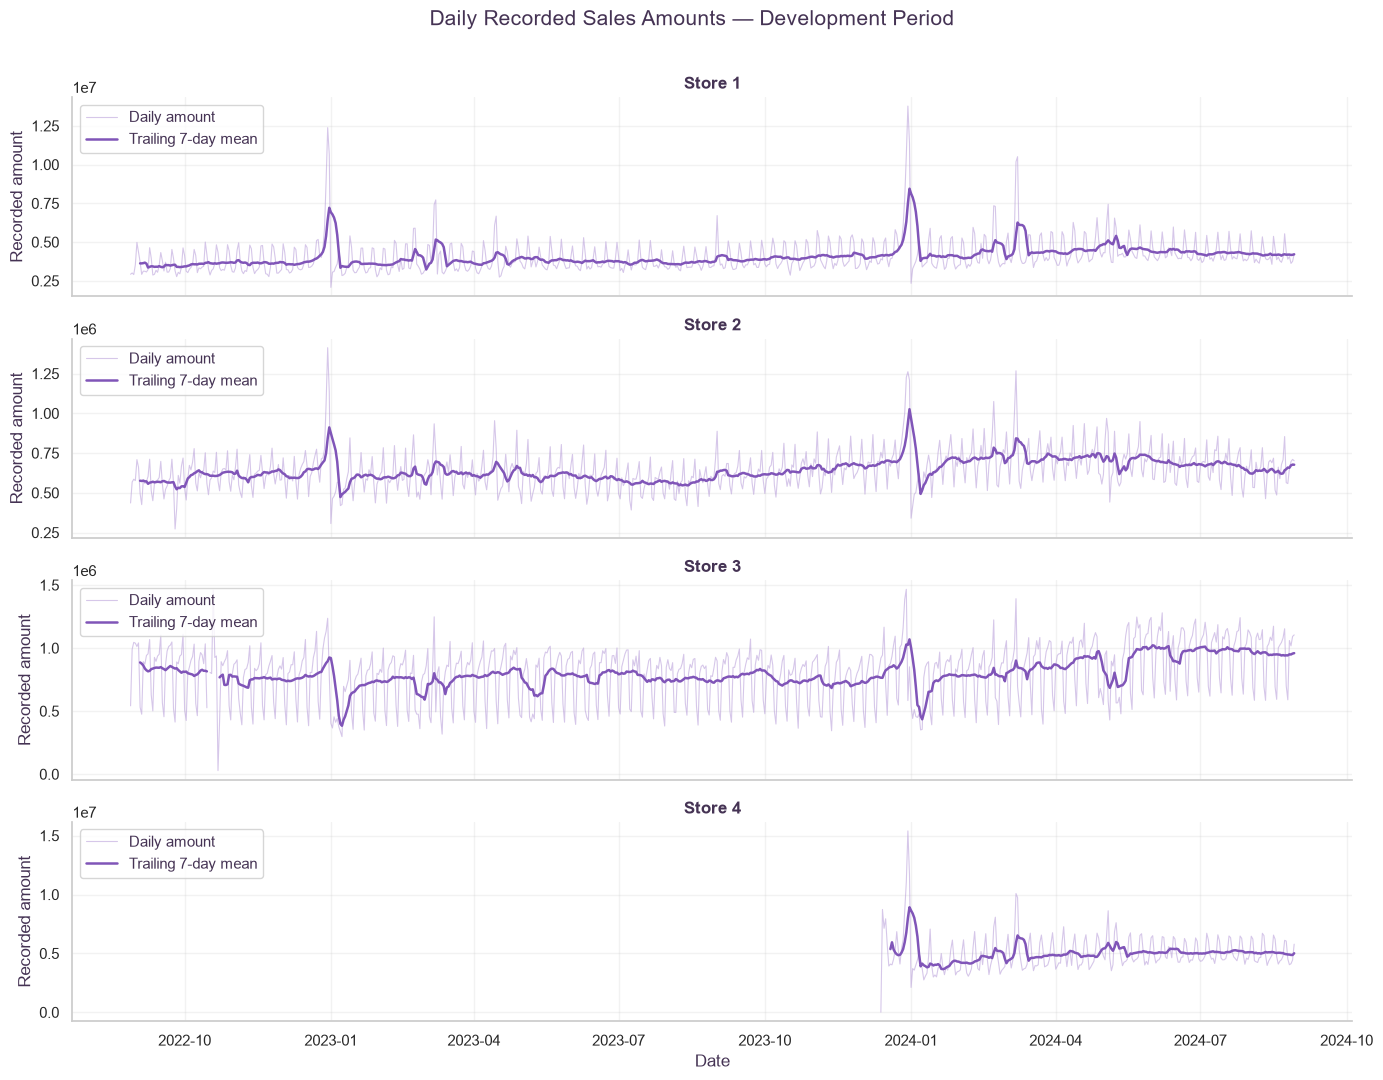

In [10]:
daily_amount = (
    sales_dev
    .groupby(["date", "store_id"], observed=True)["sum_total"]
    .sum(min_count=1)
    .unstack("store_id")
    .sort_index()
)

dev_calendar = pd.date_range(
    sales_dev["date"].min(),
    TEST_START - pd.Timedelta(days=1),
    freq="D",
)

daily_amount = daily_amount.reindex(dev_calendar)
daily_amount.index.name = "date"

store_summary = pd.DataFrame({
    "observed_days": daily_amount.count(),
    "net_recorded_amount": daily_amount.sum(min_count=1),
    "mean_daily_amount": daily_amount.mean(),
    "median_daily_amount": daily_amount.median(),
    "p10_daily_amount": daily_amount.quantile(0.10),
    "p90_daily_amount": daily_amount.quantile(0.90),
    "nonpositive_observed_days": daily_amount.le(0).sum(),
})

store_summary.index.name = "store_id"
display(store_summary)

rolling_amount = daily_amount.rolling(
    window=7, min_periods=7
).mean()

fig, axes = plt.subplots(
    len(daily_amount.columns), 1,
    figsize=(14, 11),
    sharex=True,
)

for ax, store_id in zip(axes, daily_amount.columns):
    ax.plot(
        daily_amount.index,
        daily_amount[store_id],
        color=COLORS["lavender"],
        alpha=0.55,
        linewidth=0.8,
        label="Daily amount",
    )
    ax.plot(
        rolling_amount.index,
        rolling_amount[store_id],
        color=COLORS["purple"],
        linewidth=1.8,
        label="Trailing 7-day mean",
    )
    ax.set_title(f"Store {store_id}")
    ax.set_ylabel("Recorded amount")
    ax.legend(loc="upper left")

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Daily Recorded Sales Amounts — Development Period",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

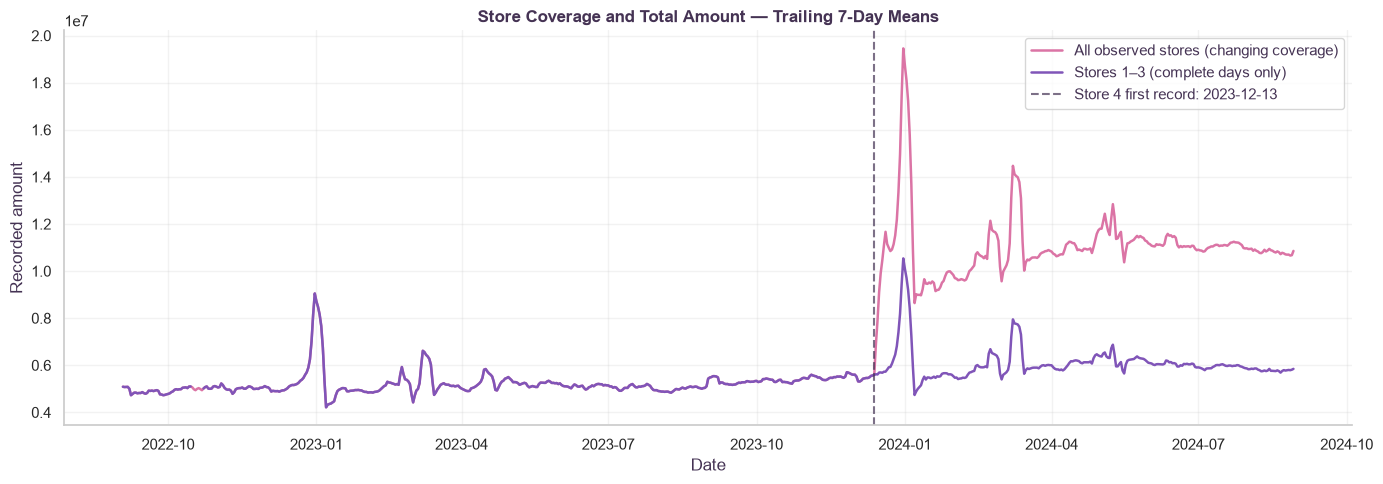

In [11]:
fixed_store_ids = [1, 2, 3]

fixed_group_amount = daily_amount[fixed_store_ids].sum(
    axis=1,
    min_count=len(fixed_store_ids),
)

all_observed_amount = daily_amount.sum(axis=1, min_count=1)

comparison = pd.DataFrame({
    "All observed stores (changing coverage)": all_observed_amount,
    "Stores 1–3 (complete days only)": fixed_group_amount,
})

comparison_rolling = comparison.rolling(
    window=7, min_periods=7
).mean()

fig, ax = plt.subplots(figsize=(14, 5))

for column, color in zip(
    comparison_rolling.columns,
    [COLORS["pink"], COLORS["purple"]],
):
    ax.plot(
        comparison_rolling.index,
        comparison_rolling[column],
        label=column,
        color=color,
        linewidth=1.8,
    )

store4_first_date = daily_amount[4].first_valid_index()
ax.axvline(
    store4_first_date,
    color=COLORS["dark"],
    linestyle="--",
    alpha=0.7,
    label=f"Store 4 first record: {store4_first_date:%Y-%m-%d}",
)

ax.set_title("Store Coverage and Total Amount — Trailing 7-Day Means")
ax.set_xlabel("Date")
ax.set_ylabel("Recorded amount")
ax.legend()
plt.tight_layout()
plt.show()

### Initial temporal patterns

Stores differ substantially in sales magnitude. However, their full-period
averages cover different date ranges, so we need a common observation window
for a fairer comparison.

The daily curves show recurring short-term fluctuations that suggest
weekday effects. Pronounced peaks appear near the ends of 2022 and 2023;
holiday demand is a possible explanation that requires further investigation.

The first appearance of store 4 substantially increases the combined amount.
The fixed group of stores 1–3 does not show an equivalent sustained increase,
so changing store coverage explains a substantial part of the aggregate shift.

We also observe sharp troughs, particularly in store 3. We retain these
observations until we examine their dates and underlying records.

## 8. Common-period comparison and weekday profiles

We compare stores over their shared development period, starting on
2023-12-13. We use dates with records for every store and report the
number of observations.

We then examine median daily amounts by weekday. We express each weekday
median relative to the store's overall daily median to compare profile
shapes across stores of different sizes.

These profiles are descriptive. They do not isolate weekday effects from
holidays, promotions, trends, or changes in assortment.

In [12]:
common_start = max(
    daily_amount[column].first_valid_index()
    for column in daily_amount.columns
)

common_daily = (
    daily_amount.loc[common_start:]
    .dropna(how="any")
    .copy()
)

common_summary = pd.DataFrame({
    "observed_days": common_daily.count(),
    "mean_daily_amount": common_daily.mean(),
    "median_daily_amount": common_daily.median(),
    "p10_daily_amount": common_daily.quantile(0.10),
    "p90_daily_amount": common_daily.quantile(0.90),
})

common_summary.index.name = "store_id"

print(
    f"Common period: {common_daily.index.min():%Y-%m-%d} "
    f"to {common_daily.index.max():%Y-%m-%d}"
)
display(common_summary)

Common period: 2023-12-13 to 2024-08-29


,observed_days,mean_daily_amount,median_daily_amount,p10_daily_amount,p90_daily_amount
store_id,,,,,
1,261,"4,496,531.490","4,063,603.120","3,595,501.550","5,682,648.070"
2,261,"699,540.886","694,763.390","549,590.440","853,966.430"
3,261,"878,899.920","935,918.920","540,448.350","1,145,934.120"
4,261,"5,014,275.413","4,610,003.530","3,632,695.140","6,646,439.060"


Median daily amounts by weekday:


store_id,1,2,3,4
Monday,"3,787,510.550","675,487.440","930,582.610","3,924,976.330"
Tuesday,"3,794,967.570","693,837.500","990,090.180","4,227,550.470"
Wednesday,"3,917,450.180","719,010.970","1,029,629.290","4,399,906.870"
Thursday,"4,222,467.195","742,791.965","1,053,443.320","4,646,563.650"
Friday,"5,635,813.450","842,341.450","1,090,241.660","6,265,219.990"
Saturday,"4,972,997.090","646,157.300","663,119.090","6,505,029.270"
Sunday,"3,977,505.930","555,349.270","542,019.940","4,767,406.490"


Observed days per weekday:


store_id,1,2,3,4
Monday,37,37,37,37
Tuesday,37,37,37,37
Wednesday,38,38,38,38
Thursday,38,38,38,38
Friday,37,37,37,37
Saturday,37,37,37,37
Sunday,37,37,37,37


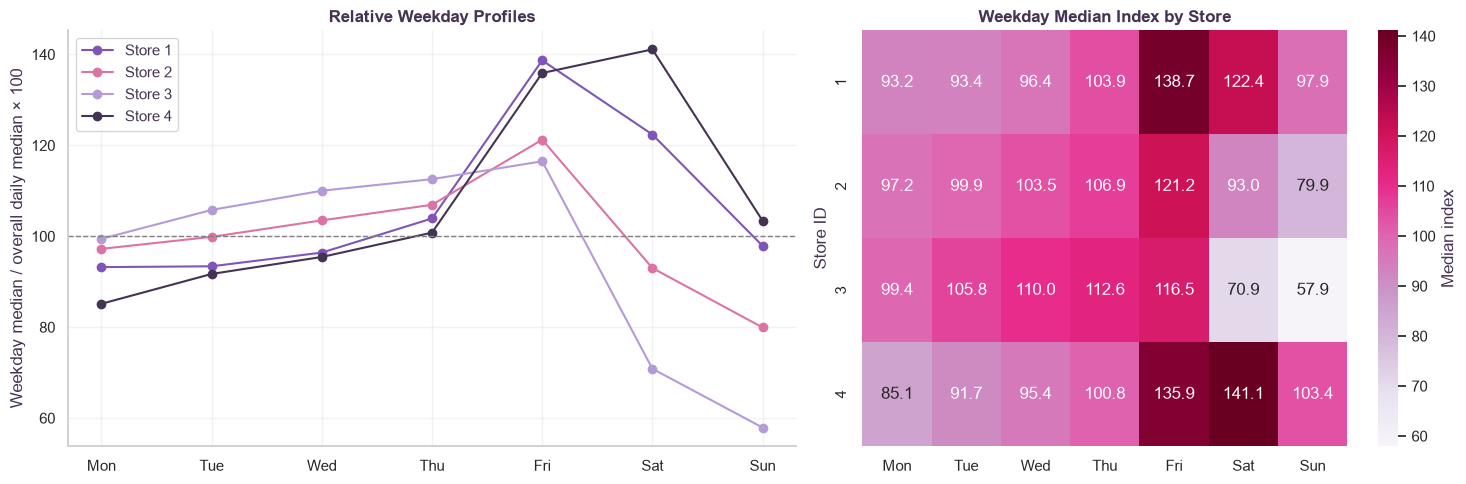

In [ ]:
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

weekday_medians = (
    common_daily
    .groupby(common_daily.index.dayofweek)
    .median()
    .reindex(range(7))
)

weekday_counts = (
    common_daily
    .groupby(common_daily.index.dayofweek)
    .count()
    .reindex(range(7))
)

weekday_index = (
    weekday_medians
    .div(common_daily.median(), axis="columns")
    .mul(100)
)

weekday_medians.index = weekday_names
weekday_counts.index = weekday_names
weekday_index.index = weekday_names

print("Median daily amounts by weekday:")
display(weekday_medians)

print("Observed days per weekday:")
display(weekday_counts)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5),
    gridspec_kw={"width_ratios": [1.2, 1]},
)

store_colors = [
    COLORS["purple"], COLORS["pink"],
    COLORS["lavender"], COLORS["dark"],
]

for store_id, color in zip(weekday_index.columns, store_colors):
    axes[0].plot(
        range(7),
        weekday_index[store_id],
        marker="o",
        color=color,
        label=f"Store {store_id}",
    )

axes[0].axhline(100, color="grey", linestyle="--", linewidth=1)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(
    [name[:3] for name in weekday_names]
)
axes[0].set_title("Relative Weekday Profiles")
axes[0].set_ylabel("Weekday median / overall daily median × 100")
axes[0].legend()

sns.heatmap(
    weekday_index.T,
    annot=True,
    fmt=".1f",
    cmap="PuRd",
    center=100,
    ax=axes[1],
    cbar_kws={"label": "Median index"},
)

axes[1].set_title("Weekday Median Index by Store")
axes[1].set_xlabel("")
axes[1].set_ylabel("Store ID")
axes[1].set_xticklabels(
    [name[:3] for name in weekday_names],
    rotation=0,
)

plt.tight_layout()
plt.show()